# Question accuracy for one model

Which of several questions (prompts) gets the most images right, compared with the annotated ground truth?

**How to use:** fill in the two paths in the next cell and run all cells. Tables and plots are saved in `comparison_results/` next to the result file.

In [1]:
# ============ SETTINGS: the only cell you need to change ============
RESULTS_FILE = "../emotions_output/emotions_data_out.csv"   # csv file with the model answers
IMAGE_DIR = "../emotions_output/emo_data"                   # folder with the images

**Other datasets** – the dataset (emotions, politicians or symbols) is detected from the image names in the result file, so only the paths change, e.g.:
```python
RESULTS_FILE = "../politicians_output/Delia/data_out_politicians_Qwen-VL-3B.csv"
IMAGE_DIR = "../politicians_output/politicians_nonpoliticians_dataset_final/politicians_nonpoliticians_dataset"

RESULTS_FILE = "../symbols_output/results/merged_coded_symbols.csv"
IMAGE_DIR = "../symbols_output/images/symbol_images"
```
The result file can be an ammico output (`filename` + `vqa`), a table with one answer column per model, or the coded table of the symbols package. Questions, ground truth and expected answers are defined in `DATASETS` in `vqa_eval_utils.py`.

## 1. Data and questions

In [2]:
import vqa_eval_utils as U

run = U.load(RESULTS_FILE, IMAGE_DIR, "question_accuracy_single_model")
assert len(run.models) == 1, f"the file contains several models {run.models}: use question_accuracy_models.ipynb"
U.show_questions(run)

dataset: emotions  |  models: emotions_data_out
images: 300 in the results, 300 with ground truth, 0 found in ../emotions_output/emo_data
output folder: ../emotions_output/comparison_results/question_accuracy_single_model


,type,style,question,expected answer (label -> answer)
qid,,,,
Q1,polarity,<pandas.io.formats.style.Styler object at 0x769ff4666c60>,Does the picture show any positive or negative emotional content?,"positive -> positive, negative -> negative, neutral -> none"
Q2,polarity,<pandas.io.formats.style.Styler object at 0x769ff4666c60>,"Does the picture show any positive or negative emotional content? Answer as applicable: positive, negative, both, none, or DK. Do not guess.","positive -> positive, negative -> negative, neutral -> none"
Q3,negative,<pandas.io.formats.style.Styler object at 0x769ff4666c60>,Does the picture show any negative emotional content?,"positive -> no, negative -> yes, neutral -> no"
Q4,negative,<pandas.io.formats.style.Styler object at 0x769ff4666c60>,"Does the picture show any negative emotional content? Answer as applicable: yes, no or DK. Do not guess.","positive -> no, negative -> yes, neutral -> no"
Q5,negative,<pandas.io.formats.style.Styler object at 0x769ff4666c60>,"Does the picture show any negative emotional content, either because of the facial or body displays of the individuals, or because of what it depicts, or because of the text it contains? Answer as...","positive -> no, negative -> yes, neutral -> no"
Q6,positive,<pandas.io.formats.style.Styler object at 0x769ff4666c60>,Does the picture show any positive emotional content?,"positive -> yes, negative -> no, neutral -> no"
Q7,positive,<pandas.io.formats.style.Styler object at 0x769ff4666c60>,"Does the picture show any positive emotional content? Answer as applicable: yes, no or DK. Do not guess.","positive -> yes, negative -> no, neutral -> no"
Q8,positive,<pandas.io.formats.style.Styler object at 0x769ff4666c60>,"Does the picture show any positive emotional content, either because of the facial and body displays of the individuals, or because of what it depicts, or because of the text it contains? Answer a...","positive -> yes, negative -> no, neutral -> no"


## 2. From free text to answers
Each answer is mapped to a category (yes / no / dk, …) by the rules of its question type. `exact`, `first` and `package_code` are safe; the keyword rules (`kw_*`) are heuristics, so read the sample of raw answers below against their `normalised` value.

In [3]:
U.show_normalisation(run)

,,exact,first,kw_none,kw_polarity
qid,model,,,,
Q1,emotions_data_out,290,0,4,6
Q2,emotions_data_out,300,0,0,0
Q3,emotions_data_out,272,28,0,0
Q4,emotions_data_out,300,0,0,0
Q5,emotions_data_out,300,0,0,0
Q6,emotions_data_out,274,26,0,0
Q7,emotions_data_out,300,0,0,0
Q8,emotions_data_out,300,0,0,0


10 distinct keyword-mapped or unparsed answers (all in ../emotions_output/comparison_results/question_accuracy_single_model/mapping_review.csv); sample:


,model,qid,rule,normalised,raw
2,emotions_data_out,Q1,kw_none,none,The image does not contain any explicit positive or negative emotional content. It is a straightforward photograph of an urban street scene with no visible emotions or expressions.
8,emotions_data_out,Q1,kw_polarity,positive,"The picture shows a positive emotional content as it depicts emergency services responding to a flood situation, which is typically associated with helping and saving lives during adverse weather ..."
4,emotions_data_out,Q1,kw_polarity,negative,"The picture shows a somber and respectful emotional content, as it depicts a funeral scene with people gathered around a casket in a cemetery."
9,emotions_data_out,Q1,kw_polarity,positive,"The picture shows a positive emotional content as it depicts a firefighter actively working to extinguish a fire, which is an essential and commendable action in emergency situations."
1,emotions_data_out,Q1,kw_none,none,"The image does not contain any explicit emotional content. It appears to be a formal press conference with a man speaking into microphones, likely addressing the media. The context suggests a poli..."
3,emotions_data_out,Q1,kw_none,none,"The image does not contain any explicit emotional content. It is a weather map showing the forecast for Switzerland on May 28, 2024. The map includes various locations with their respective temper..."


> **Result:** 300 images have results and a ground-truth label (label: number of images – positive: 99, negative: 99, neutral: 84, unclear: 18). 10 of 2400 answers needed keyword rules and 0 remain unparsed.

## 3. Accuracy per question
**Accuracy** = share of images whose (normalised) answer matches the expected answer from the ground truth. DK, unclear and unparsed answers count as **wrong**; images without an expected answer (e.g. label `unclear`) are not scored.
The **majority baseline** is the accuracy of always giving the most frequent expected answer – a question is only useful if it beats it clearly. Error bars are 95% Wilson confidence intervals.

,qid,target,style,n,correct,accuracy,ci_low,ci_high,dk_share,majority_baseline
0,Q1,polarity,open,282,194,0.688,0.632,0.739,0.000,0.351
1,Q2,polarity,constrained,282,201,0.713,0.657,0.762,0.000,0.351
2,Q3,negative,open,282,250,0.887,0.844,0.918,0.000,0.649
3,Q4,negative,constrained,282,241,0.855,0.809,0.891,0.007,0.649
4,Q5,negative,constrained+cues,282,232,0.823,0.774,0.863,0.000,0.649
5,Q6,positive,open,282,247,0.876,0.832,0.909,0.000,0.649
6,Q7,positive,constrained,282,243,0.862,0.817,0.897,0.011,0.649
7,Q8,positive,constrained+cues,282,257,0.911,0.872,0.939,0.000,0.649


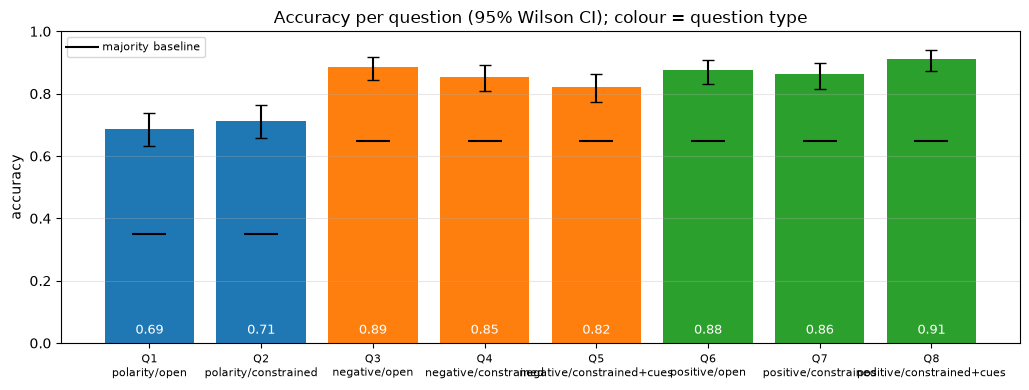

> **Result:** The most accurate question is Q8 (0.91, 95% CI 0.87–0.94), the least accurate Q1 (0.69). DK answers play no role (below 5% for every question). 

In [4]:
acc = U.show_accuracy(run)

## 4. Accuracy per image group
The same accuracy for each image group: a low value shows which kind of image makes a question fail.

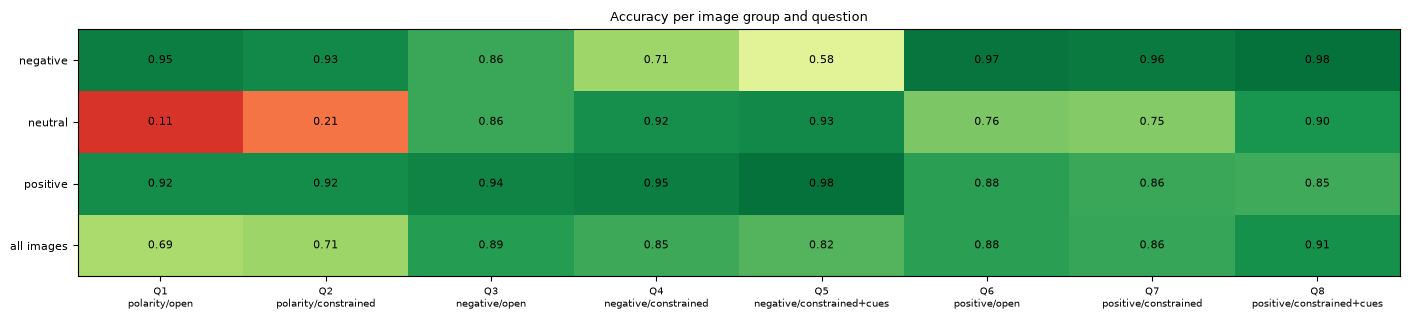

> **Result:** The weakest combinations are neutral with Q1 (0.11) and neutral with Q2 (0.21). 

In [5]:
U.show_groups(run, acc)

## 5. Hardest images
The images with the largest share of wrong answers. For each image: the image, the answer generated for every question (`read as` = the normalised answer that is scored), the expected answer, and which answers are wrong. Errors on every question point to a hard image or a questionable label; errors on some questions point to the wording.

6 of 282 scored images have at least 88% wrong answers; the 6 hardest are shown (all in ../emotions_output/comparison_results/question_accuracy_single_model/image_difficulty.csv).


### `775034_01.jpg`  
label: **positive**  |  group: positive  |  folder: neutral_vis_positive_text  |  **8 of 8 answers wrong**

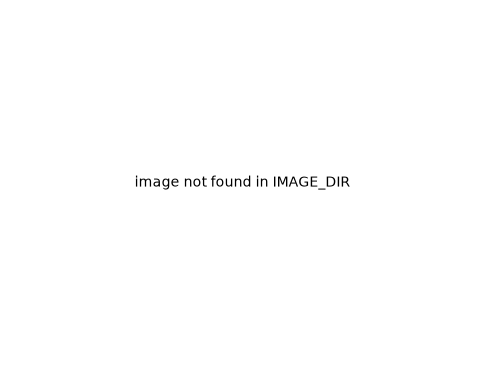

,question,generated answer,read as,expected,
Q1,polarity/open,Negative,negative,positive,✗ wrong
Q2,polarity/constrained,negative,negative,positive,✗ wrong
Q3,negative/open,Yes,yes,no,✗ wrong
Q4,negative/constrained,Yes.,yes,no,✗ wrong
Q5,negative/constrained+cues,yes,yes,no,✗ wrong
Q6,positive/open,No,no,yes,✗ wrong
Q7,positive/constrained,No,no,yes,✗ wrong
Q8,positive/constrained+cues,no,no,yes,✗ wrong


> **Result:** Wrong answers: Q1 ("negative" instead of "positive"), Q2 ("negative" instead of "positive"), Q3 ("yes" instead of "no"), Q4 ("yes" instead of "no"), Q5 ("yes" instead of "no"), Q6 ("no" instead of "yes"), Q7 ("no" instead of "yes") and Q8 ("no" instead of "yes").

### `790356_01.jpg`  
label: **positive**  |  group: positive  |  folder: neutral_vis_positive_text  |  **8 of 8 answers wrong**

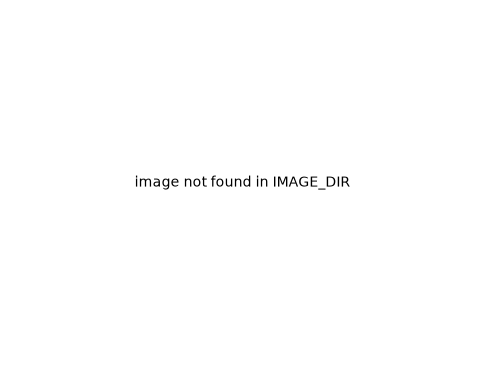

,question,generated answer,read as,expected,
Q1,polarity/open,Negative,negative,positive,✗ wrong
Q2,polarity/constrained,negative,negative,positive,✗ wrong
Q3,negative/open,Yes,yes,no,✗ wrong
Q4,negative/constrained,yes,yes,no,✗ wrong
Q5,negative/constrained+cues,yes,yes,no,✗ wrong
Q6,positive/open,No,no,yes,✗ wrong
Q7,positive/constrained,No,no,yes,✗ wrong
Q8,positive/constrained+cues,No,no,yes,✗ wrong


> **Result:** Wrong answers: Q1 ("negative" instead of "positive"), Q2 ("negative" instead of "positive"), Q3 ("yes" instead of "no"), Q4 ("yes" instead of "no"), Q5 ("yes" instead of "no"), Q6 ("no" instead of "yes"), Q7 ("no" instead of "yes") and Q8 ("no" instead of "yes").

### `512463.jpeg`  
label: **positive**  |  group: positive  |  folder: folder2  |  **7 of 8 answers wrong**

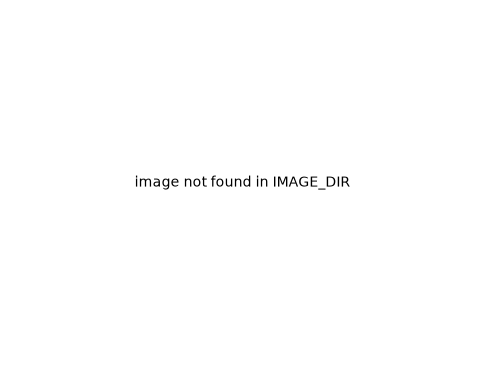

,question,generated answer,read as,expected,
Q1,polarity/open,Negative,negative,positive,✗ wrong
Q2,polarity/constrained,negative,negative,positive,✗ wrong
Q3,negative/open,Yes,yes,no,✗ wrong
Q4,negative/constrained,yes,yes,no,✗ wrong
Q5,negative/constrained+cues,no,no,no,✓ correct
Q6,positive/open,No,no,yes,✗ wrong
Q7,positive/constrained,no,no,yes,✗ wrong
Q8,positive/constrained+cues,no,no,yes,✗ wrong


> **Result:** Wrong answers: Q1 ("negative" instead of "positive"), Q2 ("negative" instead of "positive"), Q3 ("yes" instead of "no"), Q4 ("yes" instead of "no"), Q6 ("no" instead of "yes"), Q7 ("no" instead of "yes") and Q8 ("no" instead of "yes").

### `512598.jpeg`  
label: **positive**  |  group: positive  |  folder: folder2  |  **7 of 8 answers wrong**

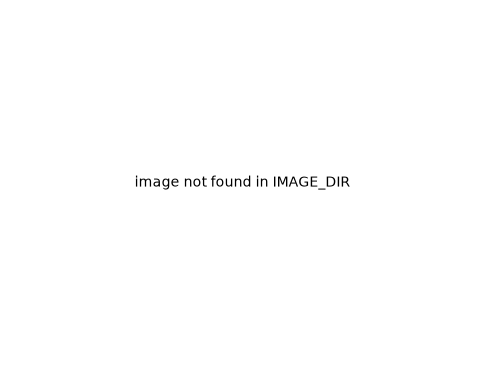

,question,generated answer,read as,expected,
Q1,polarity/open,Negative,negative,positive,✗ wrong
Q2,polarity/constrained,negative,negative,positive,✗ wrong
Q3,negative/open,"Yes, it shows negative emotional content due to the destruction and smoke.",yes,no,✗ wrong
Q4,negative/constrained,Yes.,yes,no,✗ wrong
Q5,negative/constrained+cues,no,no,no,✓ correct
Q6,positive/open,No,no,yes,✗ wrong
Q7,positive/constrained,No,no,yes,✗ wrong
Q8,positive/constrained+cues,no,no,yes,✗ wrong


> **Result:** Wrong answers: Q1 ("negative" instead of "positive"), Q2 ("negative" instead of "positive"), Q3 ("yes" instead of "no"), Q4 ("yes" instead of "no"), Q6 ("no" instead of "yes"), Q7 ("no" instead of "yes") and Q8 ("no" instead of "yes").

### `514372.jpeg`  
label: **positive**  |  group: positive  |  folder: folder2  |  **7 of 8 answers wrong**

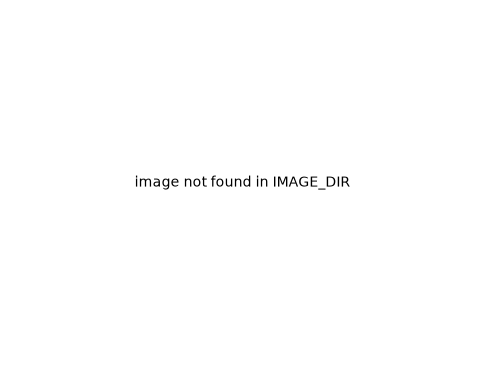

,question,generated answer,read as,expected,
Q1,polarity/open,Negative,negative,positive,✗ wrong
Q2,polarity/constrained,negative,negative,positive,✗ wrong
Q3,negative/open,Yes,yes,no,✗ wrong
Q4,negative/constrained,yes,yes,no,✗ wrong
Q5,negative/constrained+cues,no,no,no,✓ correct
Q6,positive/open,No,no,yes,✗ wrong
Q7,positive/constrained,No,no,yes,✗ wrong
Q8,positive/constrained+cues,no,no,yes,✗ wrong


> **Result:** Wrong answers: Q1 ("negative" instead of "positive"), Q2 ("negative" instead of "positive"), Q3 ("yes" instead of "no"), Q4 ("yes" instead of "no"), Q6 ("no" instead of "yes"), Q7 ("no" instead of "yes") and Q8 ("no" instead of "yes").

### `815468_04.jpg`  
label: **negative**  |  group: negative  |  folder: nonviolent_1  |  **7 of 8 answers wrong**

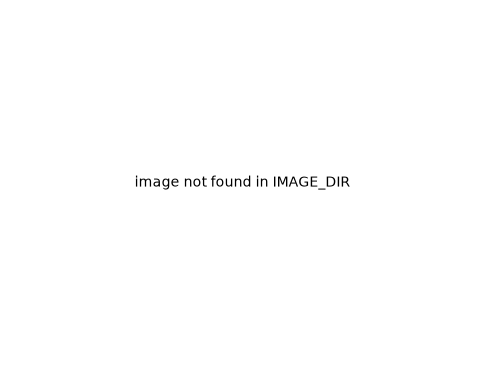

,question,generated answer,read as,expected,
Q1,polarity/open,Positive,positive,negative,✗ wrong
Q2,polarity/constrained,positive,positive,negative,✗ wrong
Q3,negative/open,No,no,yes,✗ wrong
Q4,negative/constrained,No,no,yes,✗ wrong
Q5,negative/constrained+cues,no,no,yes,✗ wrong
Q6,positive/open,"Yes, the picture shows positive emotional content.",yes,no,✗ wrong
Q7,positive/constrained,yes,yes,no,✗ wrong
Q8,positive/constrained+cues,no,no,no,✓ correct


> **Result:** Wrong answers: Q1 ("positive" instead of "negative"), Q2 ("positive" instead of "negative"), Q3 ("no" instead of "yes"), Q4 ("no" instead of "yes"), Q5 ("no" instead of "yes"), Q6 ("yes" instead of "no") and Q7 ("yes" instead of "no").

In [6]:
U.show_hardest_images(run, n=6)   # n = number of images shown